# Windows Living-off-the-Land(LotL) Attack Detection Using Short- and Long-Sequence LSTM Models

**1. Connect to Google Drive**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2. Set the Dataset Folder Path**

In [2]:
folder_path = "/content/drive/MyDrive/Cybersecurity_D2"

**3. Check Files in the Dataset Folder**

In [3]:
import os

print(os.listdir(folder_path))

['scenario_manifest.csv', 'combined.csv']


**4. Upload the Scenario Manifest**

In [4]:
from google.colab import files

uploaded = files.upload()

Saving scenario_manifest (2).csv to scenario_manifest (2).csv


In [5]:
import os
import glob

manifest_files = glob.glob("scenario_manifest*.csv")

if not manifest_files:
    raise FileNotFoundError("Scenario manifest CSV was not uploaded.")

source_file = (
    "scenario_manifest.csv"
    if "scenario_manifest.csv" in manifest_files
    else manifest_files[0]
)

if source_file != "scenario_manifest.csv":
    os.replace(source_file, "scenario_manifest.csv")

manifest_path = "scenario_manifest.csv"

print("Manifest file is ready:", manifest_path)

Manifest file is ready: scenario_manifest.csv


**5. Verify Dataset and Manifest Paths**

In [6]:
import os

file_path = os.path.join(folder_path, "combined.csv")
manifest_path = "scenario_manifest.csv"

print("Dataset exists:", os.path.exists(file_path))
print("Manifest exists:", os.path.exists(manifest_path))

Dataset exists: True
Manifest exists: True


**6. Load the Combined Windows Event Dataset**

In [7]:
import csv
import pandas as pd

rows = []

with open(file_path, "r", encoding="utf-8", errors="replace", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)

    for row in reader:
        rows.append(row)

df = pd.DataFrame(rows, columns=header)

print("Dataset shape:", df.shape)

Dataset shape: (102011, 377)


**7. Select the Required Event Features**

In [8]:
selected_cols = [
    "_source.@timestamp",
    "_source.agent.id",
    "_source.data.win.system.eventID",
    "_source.data.win.eventdata.image",
    "_source.data.win.eventdata.parentImage",
    "_source.data.win.eventdata.commandLine",
    "_source.rule.mitre.id",
    "_source.rule.mitre.technique",
    "_source.rule.mitre.tactic"
]

df_small = df[selected_cols].copy()

print("Working dataset shape:", df_small.shape)
print(df_small.head())

Working dataset shape: (102011, 9)
            _source.@timestamp _source.agent.id  \
0  Nov 30, 2024 @ 20:30:08.057                0   
1   Dec 1, 2024 @ 06:24:28.026                2   
2   Dec 1, 2024 @ 06:24:29.426                2   
3   Dec 1, 2024 @ 06:24:29.441                2   
4   Dec 1, 2024 @ 06:24:29.503                2   

  _source.data.win.system.eventID _source.data.win.eventdata.image  \
0                                                                    
1                            4624                                    
2                               1  C:\\Windows\\SysWOW64\\net1.exe   
3                               1   C:\\Windows\\SysWOW64\\net.exe   
4                               1   C:\\Windows\\SysWOW64\\net.exe   

              _source.data.win.eventdata.parentImage  \
0                                                      
1                                                      
2                     C:\\Windows\\SysWOW64\\net.exe   
3  C:\\Progra

**8. Convert Event Timestamps to Datetime**

In [9]:
df_small["_source.@timestamp"] = pd.to_datetime(
    df_small["_source.@timestamp"],
    format="%b %d, %Y @ %H:%M:%S.%f",
    errors="coerce"
)

print("Total rows:", len(df_small))
print("Valid timestamps:", df_small["_source.@timestamp"].notna().sum())
print("Invalid timestamps:", df_small["_source.@timestamp"].isna().sum())

print("First date:", df_small["_source.@timestamp"].min())
print("Last date:", df_small["_source.@timestamp"].max())

Total rows: 102011
Valid timestamps: 102011
Invalid timestamps: 0
First date: 2024-10-28 08:51:44.254000
Last date: 2024-12-22 16:33:38.270000


In [10]:
# Sort all events by time
df_small = df_small.sort_values(
    by="_source.@timestamp"
).reset_index(drop=True)

print("Dataset shape:", df_small.shape)

print("\nFirst 5 timestamps:")
print(df_small["_source.@timestamp"].head())

print("\nLast 5 timestamps:")
print(df_small["_source.@timestamp"].tail())

Dataset shape: (102011, 9)

First 5 timestamps:
0   2024-10-28 08:51:44.254
1   2024-10-28 08:51:44.266
2   2024-10-28 08:51:46.784
3   2024-10-28 08:51:50.951
4   2024-10-28 08:51:50.951
Name: _source.@timestamp, dtype: datetime64[ns]

Last 5 timestamps:
102006   2024-12-22 16:33:25.515
102007   2024-12-22 16:33:25.526
102008   2024-12-22 16:33:27.673
102009   2024-12-22 16:33:29.269
102010   2024-12-22 16:33:38.270
Name: _source.@timestamp, dtype: datetime64[ns]


**9. Load and Inspect the Scenario Manifest**

In [11]:
manifest_path = "scenario_manifest.csv"
manifest = pd.read_csv(manifest_path)

print("Manifest shape:", manifest.shape)
print(manifest.head())

print("Shape:", manifest.shape)
print("\nColumns:")
print(manifest.columns.tolist())

print("\nFirst 10 rows:")
print(manifest.head(10))

Manifest shape: (36, 8)
  Scenrario_ID Scenario_Name Mitre_Groups Reported_Origin  \
0          S01     admin@338    admin@338           China   
1          S02        APT 30       APT 30           China   
2          S03          APT1         APT1           China   
3          S04         APT12        APT12           China   
4          S05         APT19        APT19           China   

                                  Simiulated Tactics  \
0  Defense Evasion; Discovery; Execution; Initial...   
1                          Execution; Initial Access   
2  Collection; Credential Access; Defense Evasion...   
3                          Execution; Initial Access   
4  Command and Control; Defense Evasion; Discover...   

                                Simulated Techniques  \
0  T1007; T1016; T1016.001; T1036.005; T1049; T10...   
1                               T1204.002; T1566.001   
2  T1003.001; T1005; T1007; T1016; T1016.001; T10...   
3                               T1204.002; T1566

**10. Extract MITRE Techniques from the Manifest**

In [12]:
import re

# Collect all MITRE technique IDs from the scenario manifest
manifest_techniques = set()

for text in manifest.iloc[:, 5].dropna().astype(str):
    manifest_techniques.update(
        re.findall(r"T\d{4}(?:\.\d{3})?", text)
    )

print("Number of unique simulated techniques:", len(manifest_techniques))
print(sorted(manifest_techniques))

Number of unique simulated techniques: 230
['T1001.002', 'T1003.001', 'T1003.002', 'T1003.003', 'T1003.004', 'T1003.005', 'T1003.006', 'T1003.008', 'T1005', 'T1007', 'T1010', 'T1012', 'T1014', 'T1016', 'T1016.001', 'T1018', 'T1021.001', 'T1021.002', 'T1021.003', 'T1021.004', 'T1021.005', 'T1021.006', 'T1025', 'T1027', 'T1027.001', 'T1027.002', 'T1027.003', 'T1027.004', 'T1030', 'T1033', 'T1036', 'T1036.003', 'T1036.004', 'T1036.005', 'T1037.001', 'T1037.003', 'T1037.004', 'T1039', 'T1040', 'T1041', 'T1046', 'T1047', 'T1048.002', 'T1049', 'T1053.002', 'T1053.003', 'T1053.005', 'T1053.006', 'T1055', 'T1055.001', 'T1055.002', 'T1055.012', 'T1056.001', 'T1057', 'T1059.001', 'T1059.002', 'T1059.003', 'T1059.004', 'T1059.005', 'T1059.006', 'T1059.007', 'T1059.008', 'T1059.010', 'T1068', 'T1069.001', 'T1069.002', 'T1070.001', 'T1070.002', 'T1070.003', 'T1070.004', 'T1070.005', 'T1070.006', 'T1071.001', 'T1071.002', 'T1071.004', 'T1072', 'T1074.001', 'T1078', 'T1078.001', 'T1078.003', 'T1078.0

**11. Check the MITRE Technique Column**

In [13]:
mitre_col = "_source.rule.mitre.id"

print("MITRE column:", mitre_col)
print("Column exists:", mitre_col in df_small.columns)

MITRE column: _source.rule.mitre.id
Column exists: True


**12. Match Event Techniques with Simulated Technique**

In [14]:
def extract_event_techniques(value):
    return set(re.findall(r"T\d{4}(?:\.\d{3})?", str(value)))

def has_manifest_technique(value):
    event_techs = extract_event_techniques(value)
    return len(event_techs.intersection(manifest_techniques)) > 0


matches_manifest = df_small[mitre_col].apply(has_manifest_technique)

print("Events matching simulated techniques:", matches_manifest.sum())
print("Events not matching simulated techniques:", (~matches_manifest).sum())

Events matching simulated techniques: 62979
Events not matching simulated techniques: 39032


**13. Create MITRE Match Labels**

In [15]:
df_small["label"] = matches_manifest.astype(int)

print(df_small["label"].value_counts())

print("\nPercentages:")
print(df_small["label"].value_counts(normalize=True) * 100)

label
1    62979
0    39032
Name: count, dtype: int64

Percentages:
label
1    61.73746
0    38.26254
Name: proportion, dtype: float64


**14. Prepare the Model Dataset**

In [16]:
model_df = df_small.drop(
    columns=[
        "_source.rule.mitre.id",
        "_source.rule.mitre.technique",
        "_source.rule.mitre.tactic"
    ]
).copy()

print("Model dataset shape:", model_df.shape)
print(model_df.columns.tolist())

Model dataset shape: (102011, 7)
['_source.@timestamp', '_source.agent.id', '_source.data.win.system.eventID', '_source.data.win.eventdata.image', '_source.data.win.eventdata.parentImage', '_source.data.win.eventdata.commandLine', 'label']


**15. Handle Missing Values in Text Features**

In [17]:
text_cols = [
    "_source.data.win.eventdata.image",
    "_source.data.win.eventdata.parentImage",
    "_source.data.win.eventdata.commandLine"
]

for col in text_cols:
    model_df[col] = model_df[col].fillna("missing").astype(str)

print(model_df[text_cols].isna().sum())
print(model_df[text_cols].head())

_source.data.win.eventdata.image          0
_source.data.win.eventdata.parentImage    0
_source.data.win.eventdata.commandLine    0
dtype: int64
  _source.data.win.eventdata.image _source.data.win.eventdata.parentImage  \
0                                                                           
1                                                                           
2                                                                           
3                                                                           
4                                                                           

  _source.data.win.eventdata.commandLine  
0                                         
1                                         
2                                         
3                                         
4                                         


**16. Prepare Categorical Features for Encoding**

In [18]:
encode_cols = [
    "_source.agent.id",
    "_source.data.win.system.eventID",
    "_source.data.win.eventdata.image",
    "_source.data.win.eventdata.parentImage",
    "_source.data.win.eventdata.commandLine"
]

for col in encode_cols:
    model_df[col] = model_df[col].fillna("missing").astype(str)

print("Categorical columns prepared:")
print(model_df[encode_cols].head())

Categorical columns prepared:
  _source.agent.id _source.data.win.system.eventID  \
0                0                                   
1                0                                   
2                0                                   
3                0                                   
4                0                                   

  _source.data.win.eventdata.image _source.data.win.eventdata.parentImage  \
0                                                                           
1                                                                           
2                                                                           
3                                                                           
4                                                                           

  _source.data.win.eventdata.commandLine  
0                                         
1                                         
2                                         
3         

**17. Calculate Time Differences Between Events**

In [19]:
# Sort by agent and timestamp first
model_df = model_df.sort_values(
    by=["_source.agent.id", "_source.@timestamp"]
).reset_index(drop=True)

# Time difference in seconds between events from the same agent
model_df["time_diff"] = (
    model_df.groupby("_source.agent.id")["_source.@timestamp"]
    .diff()
    .dt.total_seconds()
)

# First event for each agent has no previous event
model_df["time_diff"] = model_df["time_diff"].fillna(0)

print(model_df[[
    "_source.agent.id",
    "_source.@timestamp",
    "time_diff"
]].head(20))

print("\nTime difference statistics:")
print(model_df["time_diff"].describe())

   _source.agent.id      _source.@timestamp  time_diff
0                 0 2024-10-28 08:51:44.254      0.000
1                 0 2024-10-28 08:51:44.266      0.012
2                 0 2024-10-28 08:51:46.784      2.518
3                 0 2024-10-28 08:51:50.951      4.167
4                 0 2024-10-28 08:51:50.951      0.000
5                 0 2024-10-28 08:51:50.951      0.000
6                 0 2024-10-28 08:51:52.405      1.454
7                 0 2024-10-28 08:51:52.415      0.010
8                 0 2024-10-28 08:51:52.425      0.010
9                 0 2024-10-28 08:51:52.435      0.010
10                0 2024-10-28 08:51:52.445      0.010
11                0 2024-10-28 08:51:52.455      0.010
12                0 2024-10-28 08:51:52.466      0.011
13                0 2024-10-28 08:51:52.476      0.010
14                0 2024-10-28 08:51:52.486      0.010
15                0 2024-10-28 08:51:52.496      0.010
16                0 2024-10-28 08:51:52.506      0.010
17        

**18. Split Data into Training, Validation, and Test Sets**

In [20]:
train_parts = []
val_parts = []
test_parts = []

for agent_id, group in model_df.groupby("_source.agent.id"):
    group = group.sort_values("_source.@timestamp").reset_index(drop=True)

    n = len(group)
    train_end = int(n * 0.70)
    val_end = int(n * 0.85)

    train_parts.append(group.iloc[:train_end])
    val_parts.append(group.iloc[train_end:val_end])
    test_parts.append(group.iloc[val_end:])

train_df = pd.concat(train_parts).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print("\nTrain labels:")
print(train_df["label"].value_counts())

print("\nValidation labels:")
print(val_df["label"].value_counts())

print("\nTest labels:")
print(test_df["label"].value_counts())

Train: (71405, 8)
Validation: (15302, 8)
Test: (15304, 8)

Train labels:
label
1    44069
0    27336
Name: count, dtype: int64

Validation labels:
label
1    8786
0    6516
Name: count, dtype: int64

Test labels:
label
1    10124
0     5180
Name: count, dtype: int64


**19. Encode Categorical Features Using Training Data Only**

In [21]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

# Fit only on training data
train_df[encode_cols] = encoder.fit_transform(
    train_df[encode_cols]
)

# Apply the same encoder to validation and test data
val_df[encode_cols] = encoder.transform(
    val_df[encode_cols]
)

test_df[encode_cols] = encoder.transform(
    test_df[encode_cols]
)

print("Encoder fitted on training data only.")

print("\nTraining encoded features:")
print(train_df[encode_cols].head())

Encoder fitted on training data only.

Training encoded features:
   _source.agent.id  _source.data.win.system.eventID  \
0               0.0                              0.0   
1               0.0                              0.0   
2               0.0                              0.0   
3               0.0                              0.0   
4               0.0                              0.0   

   _source.data.win.eventdata.image  _source.data.win.eventdata.parentImage  \
0                               0.0                                     0.0   
1                               0.0                                     0.0   
2                               0.0                                     0.0   
3                               0.0                                     0.0   
4                               0.0                                     0.0   

   _source.data.win.eventdata.commandLine  
0                                     0.0  
1                                 

**20. Scale the Model Features**

In [22]:
from sklearn.preprocessing import StandardScaler

feature_cols = [
    "_source.agent.id",
    "_source.data.win.system.eventID",
    "_source.data.win.eventdata.image",
    "_source.data.win.eventdata.parentImage",
    "_source.data.win.eventdata.commandLine",
    "time_diff"
]

scaler = StandardScaler()

train_df[feature_cols] = scaler.fit_transform(train_df[feature_cols])

val_df[feature_cols] = scaler.transform(val_df[feature_cols])

test_df[feature_cols] = scaler.transform(test_df[feature_cols])

print(train_df[feature_cols].head())

print("\nTraining feature means:")
print(train_df[feature_cols].mean())

print("\nTraining feature std:")
print(train_df[feature_cols].std())

   _source.agent.id  _source.data.win.system.eventID  \
0         -3.667603                        -0.879875   
1         -3.667603                        -0.879875   
2         -3.667603                        -0.879875   
3         -3.667603                        -0.879875   
4         -3.667603                        -0.879875   

   _source.data.win.eventdata.image  _source.data.win.eventdata.parentImage  \
0                         -0.888228                               -0.451821   
1                         -0.888228                               -0.451821   
2                         -0.888228                               -0.451821   
3                         -0.888228                               -0.451821   
4                         -0.888228                               -0.451821   

   _source.data.win.eventdata.commandLine  time_diff  
0                               -0.443138  -0.015742  
1                               -0.443138  -0.015740  
2                      

**21. Sequence Length**

In [23]:
SHORT_SEQUENCE_LENGTH = 5

**22. Create Short Sequences for the LSTM Model**

In [24]:
import numpy as np

def create_short_sequences(data, feature_cols, sequence_length=5):
    X = []
    y = []

    for agent_id, group in data.groupby("_source.agent.id"):
        group = group.sort_values("_source.@timestamp").reset_index(drop=True)

        features = group[feature_cols].values
        labels = group["label"].values

        for i in range(len(group) - sequence_length + 1):
            X.append(features[i:i + sequence_length])
            y.append(labels[i + sequence_length - 1])

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)

**23. generate short datasets**



In [25]:
X_train_short, y_train_short = create_short_sequences(
    train_df, feature_cols, SHORT_SEQUENCE_LENGTH
)

X_val_short, y_val_short = create_short_sequences(
    val_df, feature_cols, SHORT_SEQUENCE_LENGTH
)

X_test_short, y_test_short = create_short_sequences(
    test_df, feature_cols, SHORT_SEQUENCE_LENGTH
)

print("Train:", X_train_short.shape)
print("Validation:", X_val_short.shape)
print("Test:", X_test_short.shape)

Train: (71385, 5, 6)
Validation: (15282, 5, 6)
Test: (15284, 5, 6)


**24. build the short LSTM**

In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

short_model = Sequential([
    LSTM(
        64,
        input_shape=(X_train_short.shape[1], X_train_short.shape[2])
    ),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

short_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

short_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,289 (79.25 KB)

 Trainable params: 20,289 (79.25 KB)

 Non-trainable params: 0 (0.00 B)

**25. Train the Short-Sequence LSTM Model**


In [27]:
from tensorflow.keras.callbacks import EarlyStopping

short_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

short_history = short_model.fit(
    X_train_short,
    y_train_short,
    validation_data=(X_val_short, y_val_short),
    epochs=20,
    batch_size=64,
    callbacks=[short_early_stop],
    verbose=1
)

Epoch 1/20
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8920 - loss: 0.2681 - val_accuracy: 0.8684 - val_loss: 0.3985
Epoch 2/20
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9356 - loss: 0.1793 - val_accuracy: 0.8914 - val_loss: 0.3799
Epoch 3/20
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9438 - loss: 0.1603 - val_accuracy: 0.9001 - val_loss: 0.3395
Epoch 4/20
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9484 - loss: 0.1500 - val_accuracy: 0.9194 - val_loss: 0.3040
Epoch 5/20
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9519 - loss: 0.1421 - val_accuracy: 0.9113 - val_loss: 0.3193
Epoch 6/20
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9536 - loss: 0.1346 - val_accuracy: 0.9208 - val_loss: 0.2947
Epoch 7/20
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9549 - loss: 0.1300 - val_accuracy: 0.9210 - val_loss: 0.3019
Epoch 8/20
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9558 - loss: 0.1250 -

**26. Evaluate the Model on the Test Set**



In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_prob_short = short_model.predict(X_test_short)
y_pred_short = (y_prob_short >= 0.5).astype(int).flatten()

accuracy_short = accuracy_score(y_test_short, y_pred_short)
precision_short = precision_score(y_test_short, y_pred_short)
recall_short = recall_score(y_test_short, y_pred_short)
f1_short = f1_score(y_test_short, y_pred_short)

tn, fp, fn, tp = confusion_matrix(y_test_short, y_pred_short).ravel()
fpr_short = fp / (fp + tn)

print("Accuracy:", accuracy_short)
print("Precision:", precision_short)
print("Recall:", recall_short)
print("F1-score:", f1_short)
print("False Positive Rate:", fpr_short)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_short, y_pred_short))

478/478 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Accuracy: 0.9472651138445433
Precision: 0.9750893312914752
Recall: 0.944427964006724
F1-score: 0.9595137633112316
False Positive Rate: 0.04718623090311352

Confusion Matrix:
[[4927  244]
 [ 562 9551]]


**27. Create Long Sequences for the LSTM Model**

In [29]:
import numpy as np

SEQUENCE_LENGTH = 20

def create_sequences(data, feature_cols, sequence_length=20):
    X = []
    y = []

    for agent_id, group in data.groupby("_source.agent.id"):
        group = group.sort_values("_source.@timestamp").reset_index(drop=True)

        features = group[feature_cols].values
        labels = group["label"].values

        for i in range(len(group) - sequence_length + 1):
            X.append(features[i:i + sequence_length])

            # Label of the final event in the sequence
            y.append(labels[i + sequence_length - 1])

    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int32)


X_train, y_train = create_sequences(
    train_df,
    feature_cols,
    SEQUENCE_LENGTH
)

X_val, y_val = create_sequences(
    val_df,
    feature_cols,
    SEQUENCE_LENGTH
)

X_test, y_test = create_sequences(
    test_df,
    feature_cols,
    SEQUENCE_LENGTH
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining sequence labels:")
print(np.unique(y_train, return_counts=True))

X_train: (71310, 20, 6)
y_train: (71310,)
X_val: (15207, 20, 6)
y_val: (15207,)
X_test: (15209, 20, 6)
y_test: (15209,)

Training sequence labels:
(array([0, 1], dtype=int32), array([27247, 44063]))


**28. Build and Compile the LSTM Mode**

In [30]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    LSTM(
        64,
        input_shape=(X_train.shape[1], X_train.shape[2])
    ),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,289 (79.25 KB)

 Trainable params: 20,289 (79.25 KB)

 Non-trainable params: 0 (0.00 B)

**29. Train the Long-Sequence LSTM Model**

In [31]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
1115/1115 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8988 - loss: 0.2535 - val_accuracy: 0.8741 - val_loss: 0.4832
Epoch 2/20
1115/1115 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9361 - loss: 0.1772 - val_accuracy: 0.8788 - val_loss: 0.4459
Epoch 3/20
1115/1115 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9441 - loss: 0.1562 - val_accuracy: 0.8869 - val_loss: 0.3694
Epoch 4/20
1115/1115 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9477 - loss: 0.1459 - val_accuracy: 0.9096 - val_loss: 0.3430
Epoch 5/20
1115/1115 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9506 - loss: 0.1393 - val_accuracy: 0.9085 - val_loss: 0.3264
Epoch 6/20
1115/1115 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9532 - loss: 0.1336 - val_accuracy: 0.9192 - val_loss: 0.3288
Epoch 7/20
1115/1115 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9548 - loss: 0.1279 - val_accuracy: 0.9265 - val_loss: 0.2882
Epoch 8/20
1115/1115 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9554 - loss: 0.1237 - 

**30. Evaluate the Model on the Test Set**

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Generate predictions
y_prob = model.predict(X_test)
y_pred = (y_prob >= 0.5).astype(int).flatten()

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Calculate False Positive Rate
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
fpr = fp / (fp + tn)

# Display results
results = {
    "Model": "Long-Sequence LSTM",
    "Sequence Length": 20,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "False Positive Rate": fpr
}

results_df = pd.DataFrame([results])

print(results_df)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

476/476 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
                Model  Sequence Length  Accuracy  Precision    Recall  \
0  Long-Sequence LSTM               20  0.936222   0.960081  0.942928   

   F1-score  False Positive Rate  
0  0.951427             0.076938  

Confusion Matrix:
[[4739  395]
 [ 575 9500]]


**31. Store the Model Evaluation Results**

In [33]:
results = pd.DataFrame([
    {
        "Model": "Short-Sequence LSTM",
        "Sequence Length": 5,
        "Accuracy": accuracy_short,
        "Precision": precision_short,
        "Recall": recall_short,
        "F1-score": f1_short,
        "False Positive Rate": fpr_short
    },
    {
        "Model": "Long-Sequence LSTM",
        "Sequence Length": 20,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "False Positive Rate": fpr
    }
])

print(results)

                 Model  Sequence Length  Accuracy  Precision    Recall  \
0  Short-Sequence LSTM                5  0.947265   0.975089  0.944428   
1   Long-Sequence LSTM               20  0.936222   0.960081  0.942928   

   F1-score  False Positive Rate  
0  0.959514             0.047186  
1  0.951427             0.076938  


**32. Save the Trained LSTM Model**

In [34]:
# Save Long-Sequence LSTM
long_model_path = "/content/drive/MyDrive/long_sequence_lstm.keras"
model.save(long_model_path)

# Save Short-Sequence LSTM
short_model_path = "/content/drive/MyDrive/short_sequence_lstm.keras"
short_model.save(short_model_path)

print("Saved long model to:", long_model_path)
print("Saved short model to:", short_model_path)

Saved long model to: /content/drive/MyDrive/long_sequence_lstm.keras
Saved short model to: /content/drive/MyDrive/short_sequence_lstm.keras


**33. Save the Evaluation Results**

In [35]:
results = pd.DataFrame([
    {
        "Model": "Short-Sequence LSTM",
        "Sequence Length": 5,
        "Accuracy": accuracy_short,
        "Precision": precision_short,
        "Recall": recall_short,
        "F1-score": f1_short,
        "False Positive Rate": fpr_short
    },
    {
        "Model": "Long-Sequence LSTM",
        "Sequence Length": 20,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "False Positive Rate": fpr
    }
])

results_path = "/content/drive/MyDrive/lstm_model_comparison.csv"

results.to_csv(results_path, index=False)

print(results)
print("Saved results to:", results_path)

                 Model  Sequence Length  Accuracy  Precision    Recall  \
0  Short-Sequence LSTM                5  0.947265   0.975089  0.944428   
1   Long-Sequence LSTM               20  0.936222   0.960081  0.942928   

   F1-score  False Positive Rate  
0  0.959514             0.047186  
1  0.951427             0.076938  
Saved results to: /content/drive/MyDrive/lstm_model_comparison.csv


**34. Save the Feature Scaler**

In [36]:
import joblib

scaler_path = "/content/drive/MyDrive/lstm_scaler.pkl"

joblib.dump(scaler, scaler_path)

print("Saved scaler to:", scaler_path)

Saved scaler to: /content/drive/MyDrive/lstm_scaler.pkl


**35. Save the Ordinal Encoder**

In [37]:
import joblib

encoders_path = "/content/drive/MyDrive/lstm_ordinal_encoder.pkl"

joblib.dump(encoder, encoders_path)

print("Saved OrdinalEncoder to:", encoders_path)

Saved OrdinalEncoder to: /content/drive/MyDrive/lstm_ordinal_encoder.pkl


**36. Verify the Saved Model and Preprocessing Files**

In [38]:
import os
import joblib
import tensorflow as tf
import pandas as pd

base = "/content/drive/MyDrive"

# Load both models
long_model = tf.keras.models.load_model(
    f"{base}/long_sequence_lstm.keras"
)

short_model_loaded = tf.keras.models.load_model(
    f"{base}/short_sequence_lstm.keras"
)

# Load shared preprocessing files
scaler = joblib.load(
    f"{base}/lstm_scaler.pkl"
)

encoder = joblib.load(
    f"{base}/lstm_ordinal_encoder.pkl"
)

# Load combined results
results = pd.read_csv(
    f"{base}/lstm_model_comparison.csv"
)

print("Long model loaded:", isinstance(long_model, tf.keras.Model))
print("Short model loaded:", isinstance(short_model_loaded, tf.keras.Model))
print("Scaler loaded:", scaler is not None)
print("Encoder loaded:", encoder is not None)

print("\nSaved results:")
print(results)

Long model loaded: True
Short model loaded: True
Scaler loaded: True
Encoder loaded: True

Saved results:
                 Model  Sequence Length  Accuracy  Precision    Recall  \
0  Short-Sequence LSTM                5  0.947265   0.975089  0.944428   
1   Long-Sequence LSTM               20  0.936222   0.960081  0.942928   

   F1-score  False Positive Rate  
0  0.959514             0.047186  
1  0.951427             0.076938  


**37. Confusion Matrix**

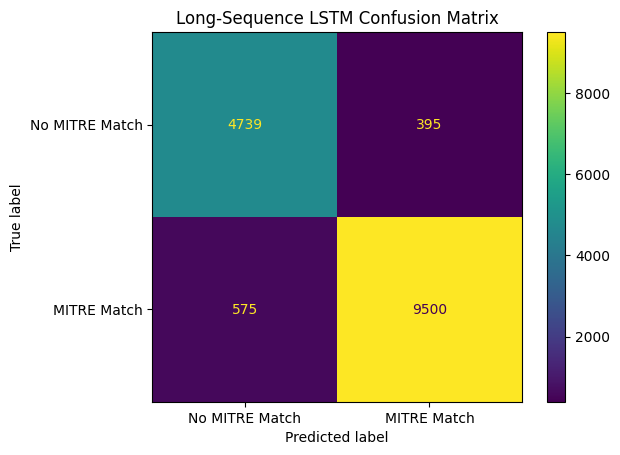

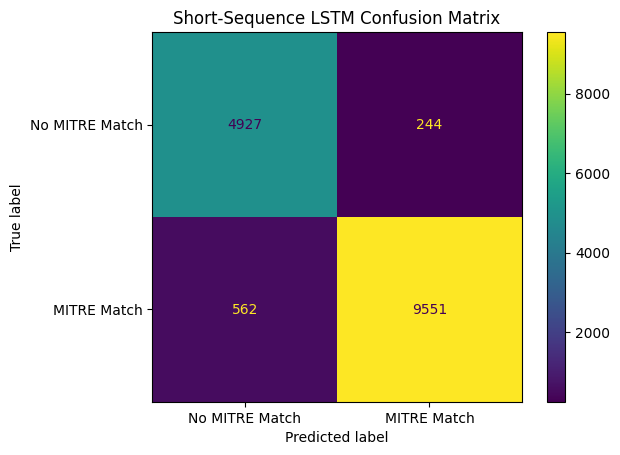

In [39]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No MITRE Match", "MITRE Match"]
)

disp.plot()
plt.title("Long-Sequence LSTM Confusion Matrix")

plt.savefig(
    "/content/drive/MyDrive/long_sequence_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()

# Short-Sequence LSTM Confusion Matrix

cm_short = confusion_matrix(y_test_short, y_pred_short)

disp_short = ConfusionMatrixDisplay(
    confusion_matrix=cm_short,
    display_labels=["No MITRE Match", "MITRE Match"]
)

disp_short.plot()
plt.title("Short-Sequence LSTM Confusion Matrix")

plt.savefig(
    "/content/drive/MyDrive/short_sequence_confusion_matrix.png",
    bbox_inches="tight"
)

plt.show()

**38. Plot Training and Validation Accuracy**

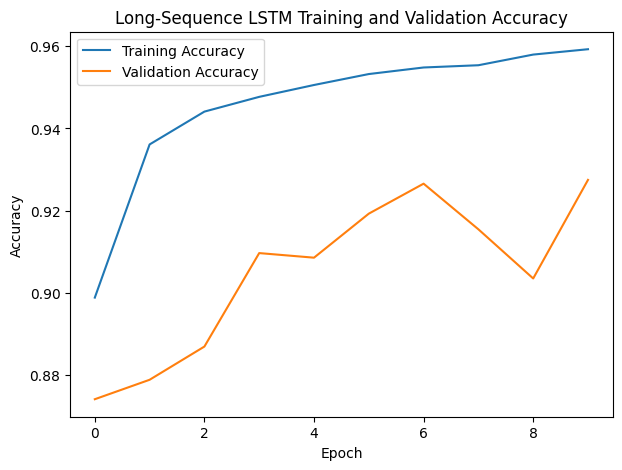

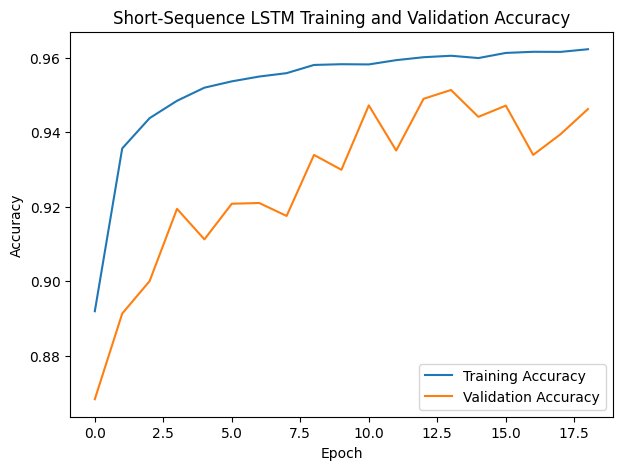

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Long-Sequence LSTM Training and Validation Accuracy")
plt.legend()

plt.savefig(
    "/content/drive/MyDrive/long_sequence_accuracy.png",
    bbox_inches="tight"
)

plt.show()

# Short-Sequence LSTM Training and Validation Accuracy

plt.figure(figsize=(7, 5))

plt.plot(short_history.history["accuracy"], label="Training Accuracy")
plt.plot(short_history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Short-Sequence LSTM Training and Validation Accuracy")
plt.legend()

plt.savefig(
    "/content/drive/MyDrive/short_sequence_accuracy.png",
    bbox_inches="tight"
)

plt.show()

**39. Plot and Save Training and Validation Loss**

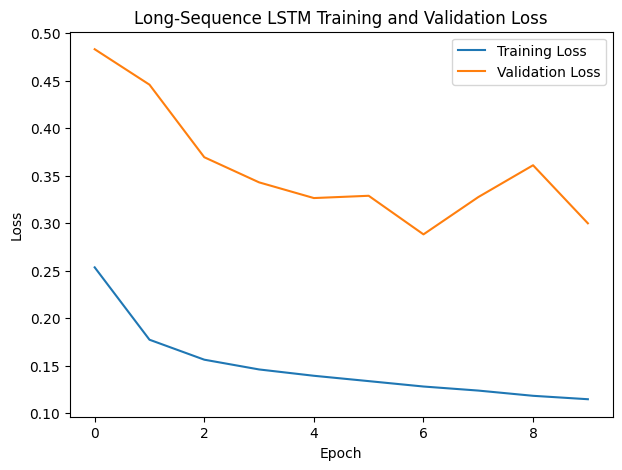

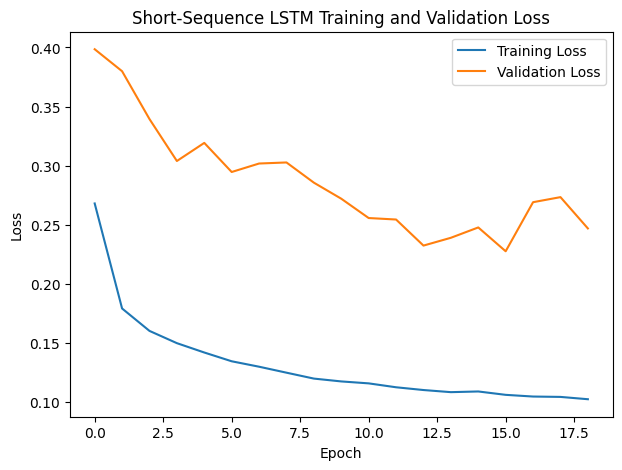

In [41]:
plt.figure(figsize=(7, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Long-Sequence LSTM Training and Validation Loss")
plt.legend()

plt.savefig(
    "/content/drive/MyDrive/long_sequence_loss.png",
    bbox_inches="tight"
)

plt.show()

# Short-Sequence LSTM Training and Validation Loss

plt.figure(figsize=(7, 5))

plt.plot(short_history.history["loss"], label="Training Loss")
plt.plot(short_history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Short-Sequence LSTM Training and Validation Loss")
plt.legend()

plt.savefig(
    "/content/drive/MyDrive/short_sequence_loss.png",
    bbox_inches="tight"
)

plt.show()

In [42]:
import pandas as pd

# Create a summary of the final model results
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "False Positive Rate"
    ],
    "Long-Sequence LSTM": [
        accuracy,
        precision,
        recall,
        f1,
        fpr
    ]
})

# Save to Google Drive
output_path = "/content/drive/MyDrive/Long_Sequence_Final_Results.xlsx"

final_results.to_excel(output_path, index=False)

print("Results saved successfully!")
print(output_path)

import pandas as pd

# Create a summary of the final model results
final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "False Positive Rate"
    ],
    "Long-Sequence LSTM": [
        accuracy,
        precision,
        recall,
        f1,
        fpr
    ],
    "Short-Sequence LSTM": [
        accuracy_short,
        precision_short,
        recall_short,
        f1_short,
        fpr_short
    ]
})

# Save to Google Drive
output_path = "/content/drive/MyDrive/LSTM_Final_Comparison_Results.xlsx"

final_results.to_excel(output_path, index=False)

print("Results saved successfully!")
print(output_path)

Results saved successfully!
/content/drive/MyDrive/Long_Sequence_Final_Results.xlsx
Results saved successfully!
/content/drive/MyDrive/LSTM_Final_Comparison_Results.xlsx


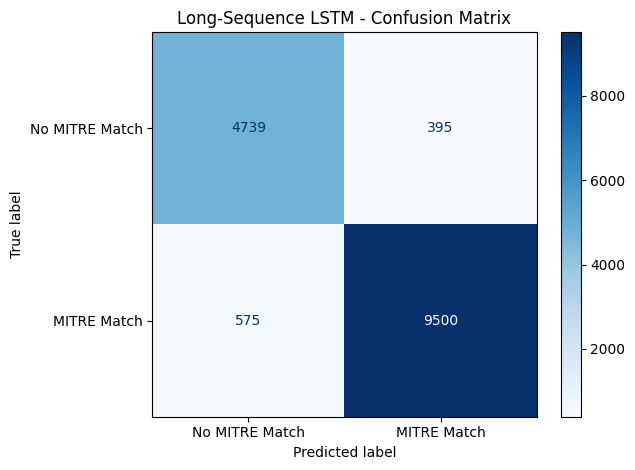

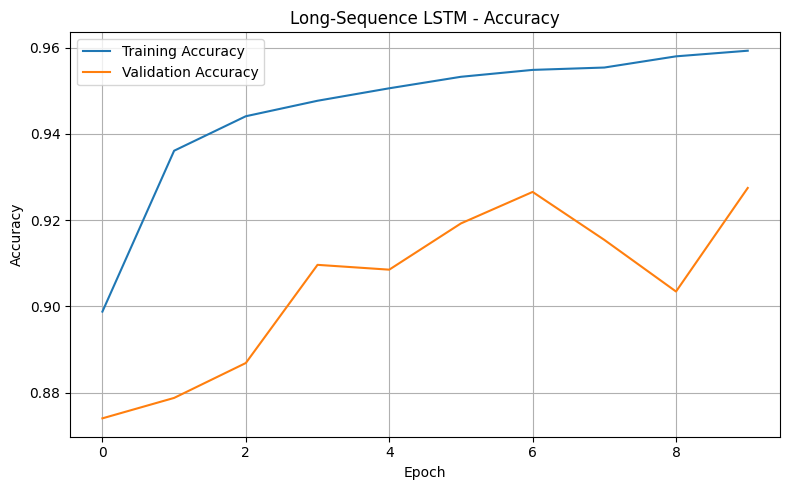

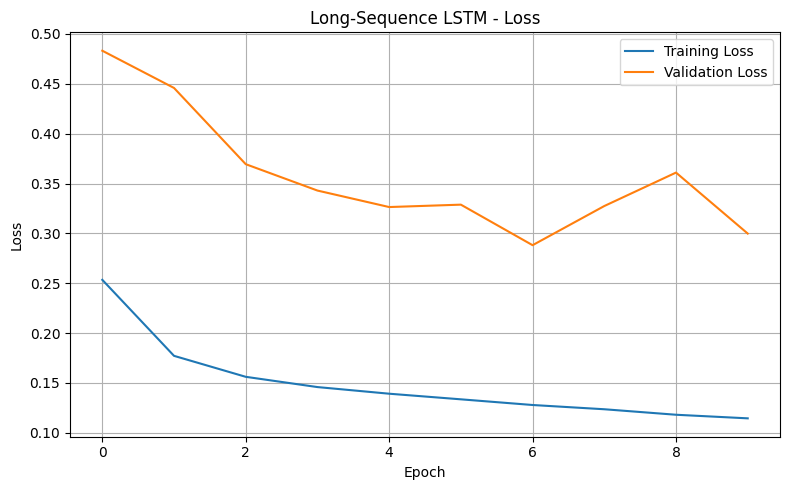

All three graphs saved successfully!
Location: /content/drive/MyDrive/Long_Sequence_Results


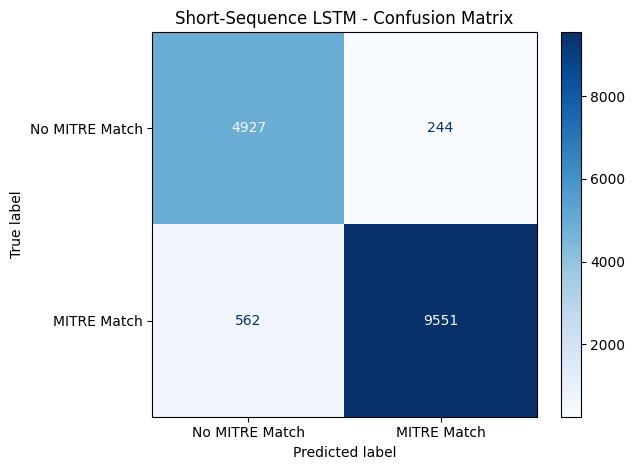

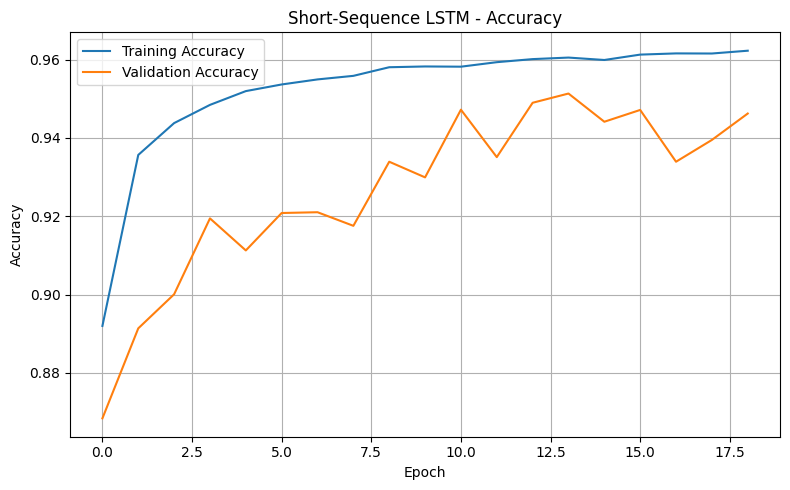

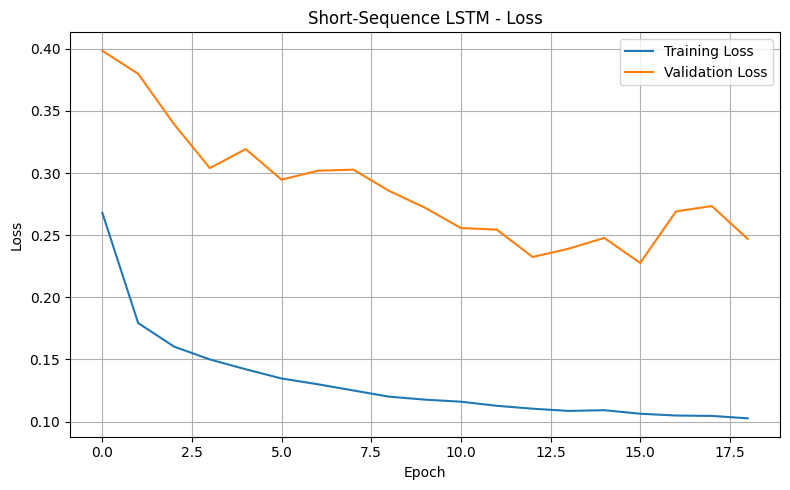

All three short-sequence graphs saved successfully!
Location: /content/drive/MyDrive/Short_Sequence_Results


In [43]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Create a folder for the graphs
output_folder = "/content/drive/MyDrive/Long_Sequence_Results"
os.makedirs(output_folder, exist_ok=True)

# 1. Save Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No MITRE Match", "MITRE Match"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Long-Sequence LSTM - Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{output_folder}/confusion_matrix.png", dpi=300)
plt.show()
plt.close()

# 2. Save Accuracy Graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Long-Sequence LSTM - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{output_folder}/accuracy_graph.png", dpi=300)
plt.show()
plt.close()

# 3. Save Loss Graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Long-Sequence LSTM - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{output_folder}/loss_graph.png", dpi=300)
plt.show()
plt.close()

print("All three graphs saved successfully!")
print("Location:", output_folder)

# Create a folder for the short-sequence graphs
short_output_folder = "/content/drive/MyDrive/Short_Sequence_Results"
os.makedirs(short_output_folder, exist_ok=True)

# 1. Save Short-Sequence Confusion Matrix
cm_short = confusion_matrix(y_test_short, y_pred_short)

disp_short = ConfusionMatrixDisplay(
    confusion_matrix=cm_short,
    display_labels=["No MITRE Match", "MITRE Match"]
)

disp_short.plot(cmap="Blues", values_format="d")
plt.title("Short-Sequence LSTM - Confusion Matrix")
plt.tight_layout()
plt.savefig(f"{short_output_folder}/confusion_matrix.png", dpi=300)
plt.show()
plt.close()

# 2. Save Short-Sequence Accuracy Graph
plt.figure(figsize=(8, 5))
plt.plot(short_history.history["accuracy"], label="Training Accuracy")
plt.plot(short_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Short-Sequence LSTM - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{short_output_folder}/accuracy_graph.png", dpi=300)
plt.show()
plt.close()

# 3. Save Short-Sequence Loss Graph
plt.figure(figsize=(8, 5))
plt.plot(short_history.history["loss"], label="Training Loss")
plt.plot(short_history.history["val_loss"], label="Validation Loss")
plt.title("Short-Sequence LSTM - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{short_output_folder}/loss_graph.png", dpi=300)
plt.show()
plt.close()

print("All three short-sequence graphs saved successfully!")
print("Location:", short_output_folder)